In [16]:
from pathlib import Path
import re
import csv
import os
import pandas as pd
# from dotenv import load_dotenv
# from sqlalchemy import create_engine
# import pyarrow as pa
# import pyarrow.parquet as pq
import numpy as np

In [6]:
load_dotenv()

user = os.getenv("MYSQL_USER")
password = os.getenv("MYSQL_PASSWORD")
host = os.getenv("MYSQL_HOST")
port = os.getenv("MYSQL_PORT")
database = os.getenv("MYSQL_DATABASE")

engine = create_engine(
    f"mysql+pymysql://{user}:{password}@{host}:{port}/{database}"
)

NameError: name 'load_dotenv' is not defined

In [3]:
"""
This script is used to treat the MEROPS database and work with it. The DB includes
many .sql files necessary to create the peptidase-inhibitor-substrate relationships.
"""
merops_path = "../MEROPS/meropsweb121"
tables_path = "../MEROPS/tables"

In [9]:
# query = """
# SELECT code, organism, status
# # SELECT *
# FROM activity_status
# WHERE organism = 'human'
# """

# df = pd.read_sql(query, engine)

# print(df.head())

In [15]:
# open peptidase_inhibitor_complex.sql and read it into a pandas dataframe
query = """
SELECT complex_id, peptidase_code, inhibitor_code, inhibitor_name, Ki
FROM peptidase_inhibitor_complex;
"""

df_complex = pd.read_sql(query, engine)

# print(df_complex.head())

peptidase_counts = df_complex['peptidase_code'].value_counts()
print(peptidase_counts[peptidase_counts > 1])
print(f"Number of peptidases with more than one inhibitor: {len(peptidase_counts[peptidase_counts > 1])}")
print(f"Number of peptidases with one inhibitor: {len(peptidase_counts[peptidase_counts == 1])}")

# Check if any inhibitor appears more than once
inhibitor_counts = df_complex['inhibitor_code'].value_counts()
print(inhibitor_counts[inhibitor_counts > 1])
print(f"Number of inhibitors with more than one peptidase: {len(inhibitor_counts[inhibitor_counts > 1])}")
print(f"Number of inhibitors with one peptidase: {len(inhibitor_counts[inhibitor_counts == 1])}")

peptidase_code
S01.151    257
A02.001    233
S01.217    136
S01.001    128
S01.216    113
          ... 
M43.005      2
S53.006      2
S01.342      2
M13.012      2
C13.001      2
Name: count, Length: 646, dtype: int64
Number of peptidases with more than one inhibitor: 646
Number of peptidases with one inhibitor: 345
inhibitor_code
J04.UPW    240
J29.001    208
J01.UPW    196
J29.002    190
J05.UPW    117
          ... 
I01.055      2
J16.408      2
I04.033      2
I16.010      2
I16.015      2
Name: count, Length: 706, dtype: int64
Number of inhibitors with more than one peptidase: 706
Number of inhibitors with one peptidase: 968


In [ ]:
# # Describe the following .sql files:
# # substrate.sql, tree.sql, sequence.sql
# # Print the column names and the number of rows for each table
# tables = [
#     # "substrate", 
#     # "tree",
#     # "sequence",
#     ]

# for table in tables:
#     query = f"SELECT * FROM {table};"
#     df_table = pd.read_sql(query, engine)
#     print(f"Table: {table}")
#     print(f"Columns: {df_table.columns.tolist()}")
#     print(f"Number of rows: {len(df_table)}")
#     print(df_table.head())

In [ ]:
# carpeta = Path(r"C:\Users\guill\OneDrive - UNIR\ASSIGNATURES\TRABAJO_FIN_MASTER\DATABASES\MEROPS\meropsweb121")

# # 2. Reconocer los tipos de datos habituales de MySQL
# tipos_validos = {
#     "int", "integer", "tinyint", "smallint", "mediumint", "bigint",
#     "varchar", "char", "text", "tinytext", "mediumtext", "longtext",
#     "enum", "set", "date", "datetime", "timestamp", "time", "year",
#     "float", "double", "decimal", "numeric", "blob", "tinyblob",
#     "mediumblob", "longblob", "binary", "varbinary", "json", "bool",
#     "boolean", "bit"
# }

# # Extraer el nombre y tipo de una columna
# def extraer_columna(linea):
#     coincidencia = re.match(r"\s*`([^`]+)`\s+(.+)", linea)
#     if not coincidencia:
#         return None

#     nombre = coincidencia.group(1)
#     resto = coincidencia.group(2).strip()

#     tipo_match = re.match(
#         r"([A-Za-z]+(?:\s*\([^)]*\))?(?:\s+unsigned)?)",
#         resto,
#         re.IGNORECASE
#     )
#     if not tipo_match:
#         return None

#     tipo = tipo_match.group(1).strip()
#     tipo_base = re.match(r"[A-Za-z]+", tipo).group(0).lower()

#     if tipo_base not in tipos_validos:
#         return None

#     return {"nombre": nombre, "tipo": tipo}


# # Analizar un archivo SQL línea por línea
# def analizar_sql(archivo):
#     tabla = None
#     columnas = []
#     dentro_create = False

#     patron_create = re.compile(
#         r"CREATE\s+TABLE\s+(?:IF\s+NOT\s+EXISTS\s+)?`([^`]+)`",
#         re.IGNORECASE
#     )

#     with archivo.open("r", encoding="latin-1", errors="replace") as f:
#         for linea in f:
#             if not dentro_create:
#                 coincidencia = patron_create.search(linea)
#                 if not coincidencia:
#                     continue

#                 tabla = coincidencia.group(1)
#                 dentro_create = True

#                 # Si hay definición de columnas en la misma línea
#                 if "(" in linea:
#                     linea = linea.split("(", 1)[1]
#                     resto = linea.split(")", 1)[0]
#                     columna = extraer_columna(resto)
#                     if columna:
#                         columnas.append(columna)
#                 continue

#             # Fin de la sentencia CREATE TABLE
#             if re.match(r"\s*\)\s*(?:ENGINE|TYPE|;|$)", linea, re.IGNORECASE):
#                 break

#             columna = extraer_columna(linea)
#             if columna:
#                 columnas.append(columna)

#     return tabla, columnas


# # 3. Recorrer los archivos y generar el catálogo
# catalogo = []

# for archivo in sorted(carpeta.glob("*.sql")):
#     tabla, columnas = analizar_sql(archivo)
#     tamano_mb = archivo.stat().st_size / (1024 * 1024)

#     catalogo.append({
#         "archivo": archivo.name,
#         "tabla": tabla or "No detectada",
#         "columnas": ", ".join(c["nombre"] for c in columnas),
#         "tipos": ", ".join(
#             f"{c['nombre']}: {c['tipo']}" for c in columnas
#         ),
#         "tamano_MB": round(tamano_mb, 3)
#     })

# # 4. Mostrar el catálogo
# for item in catalogo:
#     print(f"\nArchivo: {item['archivo']}")
#     print(f"Tabla: {item['tabla']}")
#     print(f"Tamaño: {item['tamano_MB']} MB")
#     print(f"Columnas: {item['columnas']}")
#     print(f"Tipos: {item['tipos']}")

# # 5. Guardar los resultados en un CSV
# salida = carpeta / "catalogo_merops.csv"

# with salida.open("w", newline="", encoding="utf-8-sig") as f:
#     escritor = csv.DictWriter(f, fieldnames=[
#         "archivo", "tabla", "columnas", "tipos", "tamano_MB"
#     ])
#     escritor.writeheader()
#     escritor.writerows(catalogo)

# print(f"\nCatálogo guardado en: {salida}")


Archivo: activity_status.sql
Tabla: activity_status
Tamaño: 0.053 MB
Columnas: code, organism, status, comment, reference
Tipos: code: varchar(8), organism: enum('human','mouse'), status: enum('active','inactive','putative'), comment: text, reference: tinytext

Archivo: aligned_sequence.sql
Tabla: aligned_sequence
Tamaño: 166.377 MB
Columnas: MERNO, level, aligned_sequence, MERNUM, family
Tipos: MERNO: varchar(10), level: enum('family','subfamily'), aligned_sequence: mediumtext, MERNUM: int(6) unsigned, family: tinytext

Archivo: alternative_id.sql
Tabla: alternative_id
Tamaño: 314.143 MB
Columnas: sequence_id, alternative_id, alternative_id_count, type, embln_notes, genomeID, selected_for_protein
Tipos: sequence_id: varchar(20), alternative_id: varchar(50), alternative_id_count: int(10) unsigned, type: enum('uniprot','embln','emblp','trembl','pir'), embln_notes: tinytext, genomeID: int(11), selected_for_protein: enum('Yes','No')

Archivo: architecture.sql
Tabla: architecture
Tamaño: 

In [14]:
def parse_sql_values(values_str):
    """Safely parses MySQL INSERT value tuples like ('A', 1, 'B, C'), ('D', 2, NULL)

    without breaking on commas inside quotes or escaped characters.
    """
    rows = []
    current_row = []
    current_val = []
    in_quotes = False
    escape = False
    in_row = False

    for char in values_str:
        if escape:
            current_val.append(char)
            escape = False
            continue

        if char == "\\":
            escape = True
            continue

        if char in ("'", '"') and not escape:
            in_quotes = not in_quotes
            continue

        if not in_quotes:
            if char == "(":
                in_row = True
                current_row = []
                current_val = []
            elif char == ")":
                in_row = False
                val_str = "".join(current_val).strip()
                current_row.append(None if val_str.upper() == "NULL" else val_str)
                rows.append(current_row)
                current_val = []
            elif char == "," and in_row:
                val_str = "".join(current_val).strip()
                current_row.append(None if val_str.upper() == "NULL" else val_str)
                current_val = []
            else:
                if in_row:
                    current_val.append(char)
        else:
            if in_row:
                current_val.append(char)

    return rows


def convert_sql_dump_to_csv(sql_file_path, output_dir, target_tables=None):
    os.makedirs(output_dir, exist_ok=True)

    current_table = None
    in_create_table = False
    table_columns = {}

    create_re = re.compile(r"CREATE TABLE\s+`?(\w+)`?", re.IGNORECASE)
    col_re = re.compile(r"^\s*`(\w+)`")
    insert_re = re.compile(
        r"INSERT INTO\s+`?(\w+)`?\s*(?:\(([^)]+)\))?\s*VALUES\s*(.+);$",
        re.IGNORECASE,
    )

    print(f"Streaming {sql_file_path}...")

    with open(sql_file_path, "r", encoding="utf-8", errors="replace") as f:
        for line_num, line in enumerate(f, 1):
            stripped = line.strip()

            # 1. Detect table structure to grab CSV headers
            create_match = create_re.match(stripped)
            if create_match:
                current_table = create_match.group(1)
                in_create_table = True
                table_columns[current_table] = []
                continue

            if in_create_table:
                if stripped.startswith(")"):
                    in_create_table = False
                else:
                    col_match = col_re.match(line)
                    if col_match:
                        table_columns[current_table].append(col_match.group(1))
                continue

            # 2. Extract data from INSERT statements
            if stripped.upper().startswith("INSERT INTO"):
                insert_match = insert_re.match(stripped)
                if insert_match:
                    table_name = insert_match.group(1)

                    # Skip tables we don't care about (if filter is set)
                    if target_tables and table_name not in target_tables:
                        continue

                    explicit_cols = insert_match.group(2)
                    values_part = insert_match.group(3)

                    rows = parse_sql_values(values_part)
                    csv_path = os.path.join(output_dir, f"{table_name}.csv")
                    file_exists = os.path.isfile(csv_path)

                    with open(
                        csv_path, "a", newline="", encoding="utf-8"
                    ) as csv_file:
                        writer = csv.writer(csv_file)

                        # Write header once if file is newly created
                        if not file_exists:
                            if explicit_cols:
                                headers = [
                                    c.strip(" `")
                                    for c in explicit_cols.split(",")
                                ]
                                writer.writerow(headers)
                            elif (
                                table_name in table_columns
                                and table_columns[table_name]
                            ):
                                writer.writerow(table_columns[table_name])

                        writer.writerows(rows)

            if line_num % 100000 == 0:
                print(f"Processed {line_num:,} lines...")

    print("Conversion complete!")


# --- CONFIGURATION ---
if __name__ == "__main__":
    SQL_FILE = r"../MEROPS/meropsweb121/code.sql"
    OUTPUT_FOLDER = r"../MEROPS/tables"

    # Optional: Put specific table names in a list like ["sequences", "peptidase"]
    # Leave as None to export ALL tables in the SQL file
    ONLY_TABLES = None

    convert_sql_dump_to_csv(SQL_FILE, OUTPUT_FOLDER, target_tables=ONLY_TABLES)

Streaming ../MEROPS/meropsweb121/code.sql...
Conversion complete!


In [ ]:
# # Read in chunks so RAM never spikes
# chunks = pd.read_csv("../MEROPS/tables/sequence.csv", chunksize=100_000)

# df = pd.concat(chunks)

# df.to_parquet("../MEROPS/tables/sequence.parquet", index=False)

In [ ]:
"""
NOTAS DE LAS BBDD.
Tablas que contiene información relevante:
    - peptidase_inhibitor_complex: 
        · contiene las relaciones entre peptidasas e inhibidores, incluyendo el Ki.
        · columnas: complex_id, peptidase_code, inhibitor_code, inhibitor_name, Ki
        · se deberían eliminar aquellas sin Ki
    - activity_status:
        · contiene información sobre el estado de actividad de las peptidasas.
        · eliminar aquellas con status: inactive
"""

In [20]:
## Reading the sequence parquet file
# Grab just the first 15 rows
parquet_file = pq.ParquetFile("../MEROPS/tables/sequence.parquet")

first_batch = next(parquet_file.iter_batches(batch_size=25))
df_head = first_batch.to_pandas()

print(
    f"Total rows in file: {parquet_file.metadata.num_rows:,}"
)
df_head.loc[
    # columns of interest: sequence_id, merops_taxonomy_id
    :25, ["sequence_id", "merops_taxonomy_id", "architecture_mernum"]
]

# # Load first 100 rows but only columns: merops_taxonomy_id
# df_filtered = pd.read_parquet("../MEROPS/tables/sequence.parquet", columns=["merops_taxonomy_id", "sequence_id"], engine="pyarrow")
# df_filtered.head(100)

Total rows in file: 1,256,053


,sequence_id,merops_taxonomy_id,architecture_mernum
0,1708290A,sp000252,MER0017799
1,1BCCA,sp000252,MER0003448
2,1BCCB,sp000252,MER0003448
3,1ELT,sp000092,MER0000067
4,1EQ9,sp003137,MER0027244
5,1IRU_A,sp000234,MER0047593
6,1IRU_C,sp000234,MER0000550
7,1IRU_E,sp000234,MER0047593
8,1IRU_F,sp000234,MER0047329
9,1ND1,sp003071,MER0029968


## Build protease-inhibitor sequence table

This section creates `peptidase_inhibitor_sequences.csv` by joining:

1. `peptidase_inhibitor_complex.csv` for Ki and MEROPS codes.
2. `domain.sql` from the MEROPS archive for code-to-`sequence_id` mappings.
3. `sequence.csv` for amino-acid sequences.

The sequence file is streamed and only matching rows are retained. Only one preferred sequence is selected per MEROPS code: a holotype sequence when available, otherwise the first sequence alphabetically. Holotypes are **representatives**, not guarantees that the exact experimentally used protein was sequenced.

In [ ]:
from pathlib import Path
import csv
import subprocess

csv.field_size_limit(2**31 - 1)

BASE = Path("../MEROPS")
TABLES = BASE / "tables"
COMPLEX_CSV = TABLES / "peptidase_inhibitor_complex.csv"
SEQUENCE_CSV = TABLES / "sequence.csv"
ARCHIVE = BASE / "meropsweb121.tar.gz"
DOMAIN_CSV = TABLES / "domain.csv"
OUTPUT_CSV = TABLES / "peptidase_inhibitor_sequences.csv"


def parse_mysql_insert_values(values_str):
    """Parse MySQL INSERT value tuples while respecting quotes and backslashes."""
    rows = []
    row = []
    value = []
    in_quotes = False
    escape = False
    in_row = False

    for char in values_str:
        if escape:
            value.append(char)
            escape = False
        elif char == "\\":
            escape = True
        elif char == "'" and not escape:
            in_quotes = not in_quotes
        elif char == "(" and not in_quotes:
            in_row = True
            row = []
            value = []
        elif char == ")" and not in_quotes and in_row:
            text = "".join(value).strip()
            row.append(None if text.upper() == "NULL" else text)
            rows.append(row)
            in_row = False
            row = []
            value = []
        elif char == "," and not in_quotes and in_row:
            text = "".join(value).strip()
            row.append(None if text.upper() == "NULL" else text)
            value = []
        elif in_row:
            value.append(char)

    return rows


# Extract domain.sql mappings to a small CSV once.
# This table maps MEROPS codes to sequence IDs and identifies holotypes.
if not DOMAIN_CSV.exists():
    proc = subprocess.Popen(
        ["tar", "-xOzf", str(ARCHIVE), "domain.sql"],
        stdout=subprocess.PIPE,
        text=True,
        encoding="latin1",
        errors="replace",
    )

    domain_header = [
        "mernum", "code", "sequence_id", "protein", "start", "end",
        "type", "subtype", "notes", "family_type_example",
        "subfamily_type_example", "holotype", "human_est_search",
        "mouse_est_search", "rat_est_search", "est_exception",
        "for_internet",
    ]

    with DOMAIN_CSV.open("w", newline="", encoding="utf-8") as output:
        writer = csv.writer(output)
        writer.writerow(domain_header)

        for line in proc.stdout:
            stripped = line.strip()
            if not stripped.upper().startswith("INSERT INTO `DOMAIN`"):
                continue

            marker = stripped.upper().find(" VALUES ")
            if marker == -1:
                continue

            values = stripped[marker + 8:].strip()
            if values.endswith(";"):
                values = values[:-1]

            for row in parse_mysql_insert_values(values):
                if len(row) == len(domain_header):
                    writer.writerow(row)

    proc.stdout.close()
    return_code = proc.wait()
    if return_code != 0:
        raise RuntimeError("Failed to read domain.sql from MEROPS archive")


# Read the small complex table completely: there are only a few thousand rows.
with COMPLEX_CSV.open("r", encoding="latin1", newline="") as input_file:
    complexes = list(csv.DictReader(input_file, delimiter=";"))

complex_codes = {
    code
    for row in complexes
    for code in (row["peptidase_code"], row["inhibitor_code"])
}

# Read only mappings belonging to codes in the complex table.
mappings = {}
with DOMAIN_CSV.open("r", encoding="utf-8", newline="") as input_file:
    for row in csv.DictReader(input_file):
        code = row["code"]
        sequence_id = row["sequence_id"]
        if code in complex_codes and sequence_id:
            mappings.setdefault(code, []).append(row)

sequence_ids = {
    row["sequence_id"]
    for rows in mappings.values()
    for row in rows
}

# Stream sequence.csv once and retain only required sequence IDs.
sequences = {}
with SEQUENCE_CSV.open("r", encoding="utf-8-sig", newline="") as input_file:
    for row in csv.DictReader(input_file):
        sequence_id = row["sequence_id"]
        if sequence_id in sequence_ids:
            sequences[sequence_id] = row["sequence"]


def preferred_mapping(rows):
    # Holotype sequences are preferred; ties are resolved by sequence ID.
    return sorted(
        rows,
        key=lambda row: (row["holotype"] != "Yes", row["sequence_id"]),
    )[0]


fieldnames = [
    "complex_id",
    "peptidase_code", "peptidase_sequence_id", "peptidase_sequence",
    "peptidase_protein", "peptidase_start", "peptidase_end",
    "inhibitor_code", "inhibitor_sequence_id", "inhibitor_sequence",
    "inhibitor_protein", "inhibitor_start", "inhibitor_end",
    "Ki", "ref",
]

pair_count = 0
with OUTPUT_CSV.open("w", encoding="utf-8", newline="") as output_file:
    writer = csv.DictWriter(output_file, fieldnames=fieldnames)
    writer.writeheader()

    for complex_row in complexes:
        peptidase_rows = mappings.get(complex_row["peptidase_code"])
        inhibitor_rows = mappings.get(complex_row["inhibitor_code"])

        if not peptidase_rows or not inhibitor_rows:
            continue

        peptidase = preferred_mapping(peptidase_rows)
        inhibitor = preferred_mapping(inhibitor_rows)

        writer.writerow({
            "complex_id": complex_row["complex_id"],
            "peptidase_code": complex_row["peptidase_code"],
            "peptidase_sequence_id": peptidase["sequence_id"],
            "peptidase_sequence": sequences.get(peptidase["sequence_id"], ""),
            "peptidase_protein": peptidase["protein"],
            "peptidase_start": peptidase["start"],
            "peptidase_end": peptidase["end"],
            "inhibitor_code": complex_row["inhibitor_code"],
            "inhibitor_sequence_id": inhibitor["sequence_id"],
            "inhibitor_sequence": sequences.get(inhibitor["sequence_id"], ""),
            "inhibitor_protein": inhibitor["protein"],
            "inhibitor_start": inhibitor["start"],
            "inhibitor_end": inhibitor["end"],
            "Ki": complex_row["Ki"],
            "ref": complex_row["ref"],
        })
        pair_count += 1

print(f"Complex rows: {len(complexes):,}")
print(f"Unique sequence IDs requested: {len(sequence_ids):,}")
print(f"Sequences found: {len(sequences):,}")
print(f"Pair rows created: {pair_count:,}")
print(f"Output: {OUTPUT_CSV}")

## Exploratory plots for MEROPS complex and sequence tables

The plots distinguish **missing values** from values that cannot be converted to a numeric concentration. The Ki parser handles single values, ranges, and units such as `pM`, `nM`, `uM`, `mM`, and `M`. For ranges, the logarithmic midpoint is used for visualization. A range is **not** converted into a single biological measurement for later model training.

PDB coverage is estimated through the mapping:

```text
MEROPS code -> domain.sequence_id -> alternative_id(alternative_id, type="uniprot") -> seq_pdb.uniprot_acc
```

This section is based on the compact pair table, so complexes without an available sequence are reported separately.

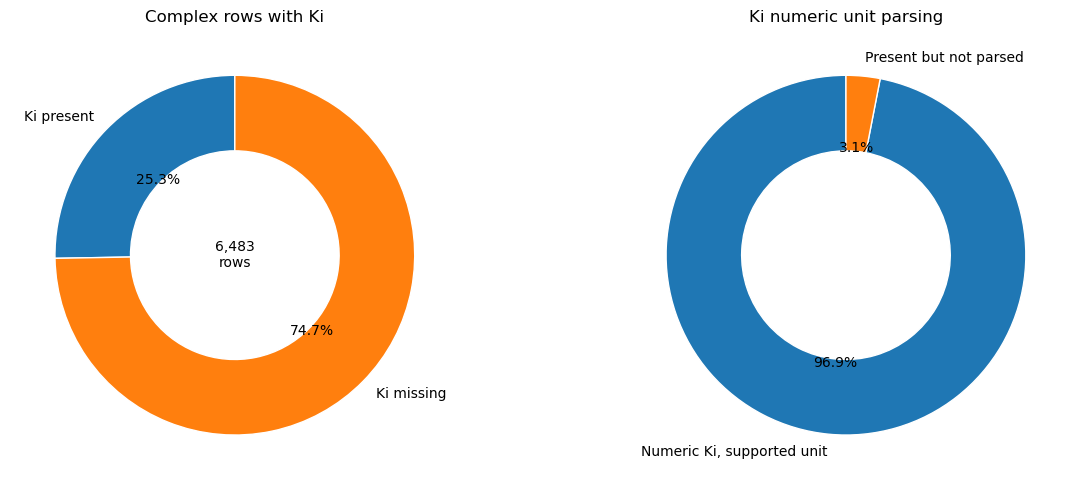

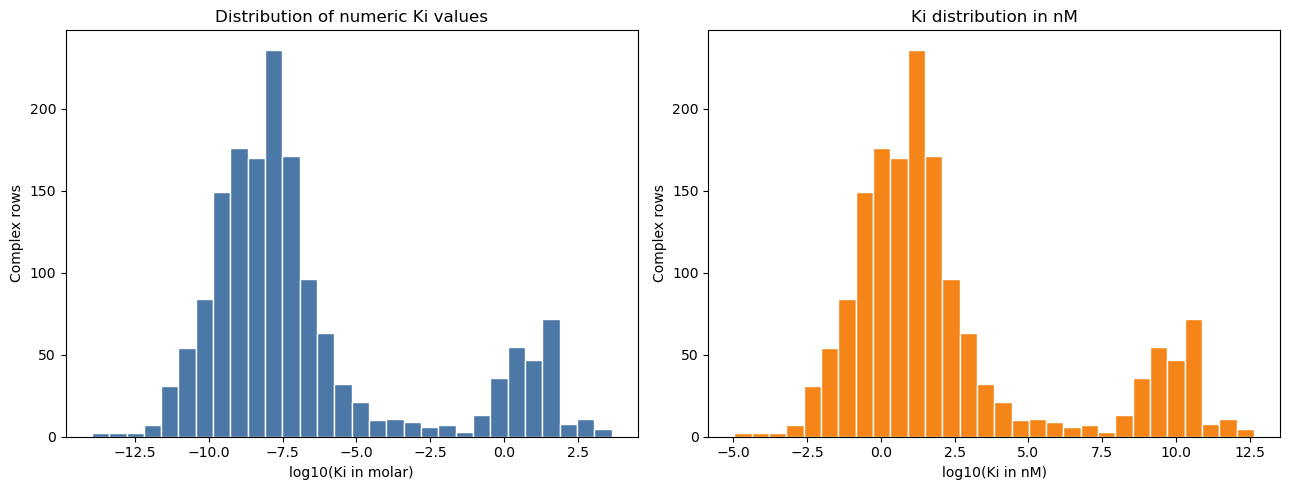

Ki availability:
Ki_available
Missing    4844
Present    1639
Name: count, dtype: int64

Ki units found:
0
nM              1223
m                267
pM                42
Unrecognized      27
nm                27
mM                25
M                  7
µM                 6
um                 4
Nm                 4
uM                 3
pm                 3
µm                 1
Name: count, dtype: int64


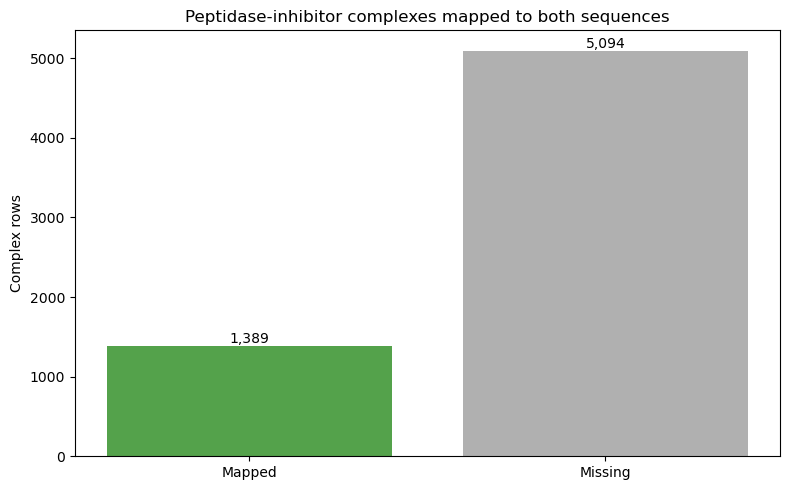

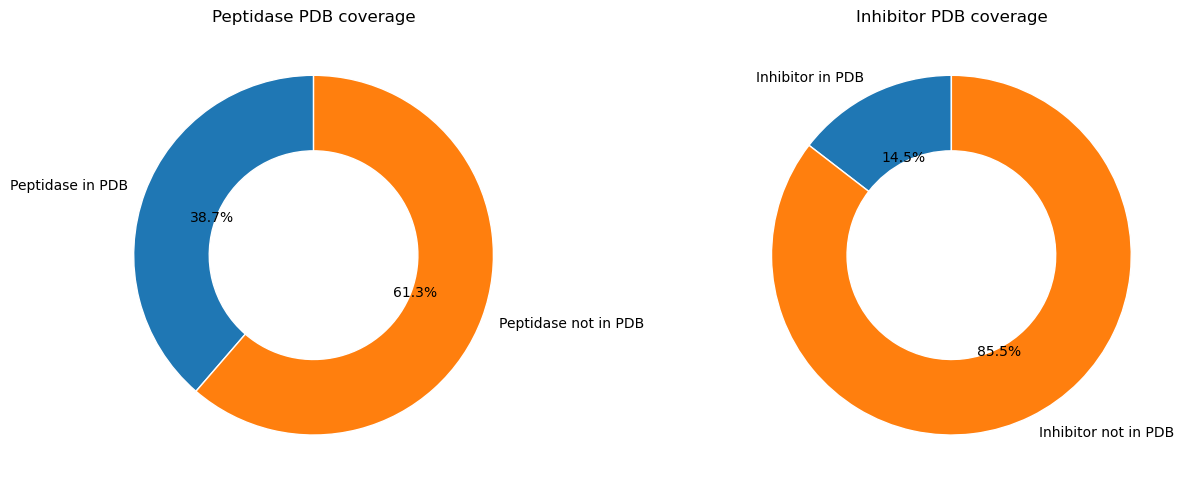

PDB coverage by compact pair row:
            peptidase  inhibitor
in_pdb            537        202
not_in_pdb        852       1187


In [17]:
import re
import matplotlib.pyplot as plt

TABLES = Path("../MEROPS/tables")
COMPLEX_CSV = TABLES / "peptidase_inhibitor_complex.csv"
PAIR_CSV = TABLES / "peptidase_inhibitor_sequences.csv"
PDB_CSV = TABLES / "seq_pdb.csv"
DOMAIN_CSV = TABLES / "domain.csv"
ARCHIVE = Path("../MEROPS/meropsweb121.tar.gz")
ALTERNATIVE_ID_CSV = TABLES / "alternative_id.csv"


def unit_to_molar(value):
    """Convert one Ki value to molar; ranges use their numeric midpoint."""
    text = str(value).strip().lower()
    if not text:
        return None

    numbers = re.findall(r"[-+]?(?:\d+(?:\.\d*)?|\.\d+)e[-+]\d+|[-+]?(?:\d+(?:\.\d*)?|\.\d+)", text)
    if not numbers:
        return None

    unit_match = re.search(r"(pm|nm|um|µm|mm|m)(?![a-z])", text)
    if not unit_match:
        return None

    factors = {"pm": 1e-12, "nm": 1e-9, "um": 1e-6, "µm": 1e-6, "mm": 1e-3, "m": 1.0}

    values = [float(number) for number in numbers[:2]]
    if len(values) == 2:
        # Logarithmic midpoint is preferable for wide concentration ranges.
        lower = values[0] * factors[unit_match.group(1)]
        upper = values[1] * factors[unit_match.group(1)]
        if lower > 0 and upper > 0:
            return (lower * upper) ** 0.5
        return None

    return values[0] * factors[unit_match.group(1)]


complexes = pd.read_csv(COMPLEX_CSV, sep=";", encoding="latin1")

# Presence and parseability are intentionally separate.
complexes["Ki_available"] = complexes["Ki"].fillna("").astype(str).str.strip().ne("")
complexes["Ki_molar"] = complexes["Ki"].map(unit_to_molar)

ki_counts = pd.Series({
    "Ki present": complexes["Ki_available"].sum(),
    "Ki missing": (~complexes["Ki_available"]).sum(),
})

parseable = complexes["Ki_molar"].notna()
parse_counts = pd.Series({
    "Numeric Ki, supported unit": parseable.sum(),
    "Present but not parsed": (complexes["Ki_available"] & ~parseable).sum(),
})

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].pie(
    ki_counts,
    labels=ki_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.42, "edgecolor": "white"},
)
axes[0].set_title("Complex rows with Ki")
axes[0].text(0, 0, f"{len(complexes):,}\nrows", ha="center", va="center")

axes[1].pie(
    parse_counts,
    labels=parse_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.42, "edgecolor": "white"},
)
axes[1].set_title("Ki numeric unit parsing")
plt.tight_layout()
plt.show()

valid_ki = complexes.loc[parseable, "Ki_molar"]
if len(valid_ki):
    log_ki = np.log10(valid_ki)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    axes[0].hist(log_ki, bins=30, color="#4C78A8", edgecolor="white")
    axes[0].set_xlabel("log10(Ki in molar)")
    axes[0].set_ylabel("Complex rows")
    axes[0].set_title("Distribution of numeric Ki values")

    ki_nM = valid_ki / 1e-9
    axes[1].hist(np.log10(ki_nM), bins=30, color="#F58518", edgecolor="white")
    axes[1].set_xlabel("log10(Ki in nM)")
    axes[1].set_ylabel("Complex rows")
    axes[1].set_title("Ki distribution in nM")

    plt.tight_layout()
    plt.show()

print("Ki availability:")
print(complexes["Ki_available"].value_counts().rename(index={True: "Present", False: "Missing"}))
print("\nKi units found:")
units = complexes.loc[complexes["Ki_available"], "Ki"].astype(str).str.extract(
    r"([pnumµ]?M)", flags=re.IGNORECASE
)[0]
print(units.fillna("Unrecognized").value_counts())


# MEROPS code coverage from the already-created pair table.
pair_table = pd.read_csv(PAIR_CSV)

coverage = pd.DataFrame({
    "Peptidase sequence": pd.Series(["Mapped", "Missing"], dtype="object"),
    "count": [
        pair_table["peptidase_sequence"].fillna("").astype(str).str.strip().ne("").sum(),
        0,
    ],
})
coverage.loc[coverage.index[1], "count"] = (
    len(complexes) - coverage.loc[coverage.index[0], "count"]
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(["Mapped", "Missing"], [len(pair_table), len(complexes) - len(pair_table)], color=["#54A24B", "#B0B0B0"])
ax.set_title("Peptidase-inhibitor complexes mapped to both sequences")
ax.set_ylabel("Complex rows")
for index, value in enumerate([len(pair_table), len(complexes) - len(pair_table)]):
    ax.text(index, value, f"{value:,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

# PDB status requires MEROPS sequence ID -> UniProt accession -> PDB.
# Extract alternative_id.sql only if it has not already been converted.
if not ALTERNATIVE_ID_CSV.exists():
    proc = subprocess.Popen(
        ["tar", "-xOzf", str(ARCHIVE), "alternative_id.sql"],
        stdout=subprocess.PIPE,
        text=True,
        encoding="latin1",
        errors="replace",
    )

    pair_ids = set(pair_table["peptidase_sequence_id"]) | set(pair_table["inhibitor_sequence_id"])

    with ALTERNATIVE_ID_CSV.open("w", newline="", encoding="utf-8") as output:
        writer = csv.writer(output)
        writer.writerow([
            "sequence_id", "alternative_id", "alternative_id_count", "type",
            "embln_notes", "genomeID", "selected_for_protein",
        ])

        for line in proc.stdout:
            stripped = line.strip()
            if not stripped.upper().startswith("INSERT INTO `ALTERNATIVE_ID`"):
                continue

            marker = stripped.upper().find(" VALUES ")
            if marker == -1:
                continue

            values = stripped[marker + 8:].strip()
            if values.endswith(";"):
                values = values[:-1]

            for row in parse_mysql_insert_values(values):
                if len(row) == 7 and row[0] in pair_ids:
                    writer.writerow(row)

    proc.stdout.close()
    if proc.wait() != 0:
        raise RuntimeError("Failed to read alternative_id.sql")

alternative = pd.read_csv(ALTERNATIVE_ID_CSV)
uniprot_ids = set(
    alternative.loc[
        alternative["type"].astype(str).str.lower().eq("uniprot"),
        "alternative_id",
    ].dropna()
)

pdb = pd.read_csv(PDB_CSV, sep=";", encoding="utf-8-sig")
pdb_ids = set(pdb["uniprot_acc"].dropna())

# Attach UniProt/PDB status to every compact pair row.
pair_sequence_ids = set(pair_table["peptidase_sequence_id"]) | set(pair_table["inhibitor_sequence_id"])
alt_lookup = alternative.loc[
    alternative["type"].astype(str).str.lower().eq("uniprot")
].groupby("sequence_id")["alternative_id"].apply(set).to_dict()


def has_pdb(sequence_id):
    accessions = alt_lookup.get(sequence_id, set())
    return bool(accessions & pdb_ids)

pair_table["peptidase_in_pdb"] = pair_table["peptidase_sequence_id"].map(has_pdb)
pair_table["inhibitor_in_pdb"] = pair_table["inhibitor_sequence_id"].map(has_pdb)

pdb_status = pd.Series({
    "Peptidase in PDB": pair_table["peptidase_in_pdb"].sum(),
    "Peptidase not in PDB": (~pair_table["peptidase_in_pdb"]).sum(),
})

inhibitor_status = pd.Series({
    "Inhibitor in PDB": pair_table["inhibitor_in_pdb"].sum(),
    "Inhibitor not in PDB": (~pair_table["inhibitor_in_pdb"]).sum(),
})

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, status, title in (
    (axes[0], pdb_status, "Peptidase PDB coverage"),
    (axes[1], inhibitor_status, "Inhibitor PDB coverage"),
):
    ax.pie(
        status,
        labels=status.index,
        autopct="%1.1f%%",
        startangle=90,
        wedgeprops={"width": 0.42, "edgecolor": "white"},
    )
    ax.set_title(title)
plt.tight_layout()
plt.show()

print("PDB coverage by compact pair row:")
print(pd.DataFrame({
    "peptidase": pd.Series({
        "in_pdb": int(pair_table["peptidase_in_pdb"].sum()),
        "not_in_pdb": int((~pair_table["peptidase_in_pdb"]).sum()),
    }),
    "inhibitor": pd.Series({
        "in_pdb": int(pair_table["inhibitor_in_pdb"].sum()),
        "not_in_pdb": int((~pair_table["inhibitor_in_pdb"]).sum()),
    }),
}))

## Partner-count distributions

These plots show network-like reuse of MEROPS entities:

- How many peptidases interact with one, two, or more inhibitors.
- How many inhibitors interact with one, two, or more peptidases.
- The same information as circular charts for the number of entities appearing exactly once versus multiple times.

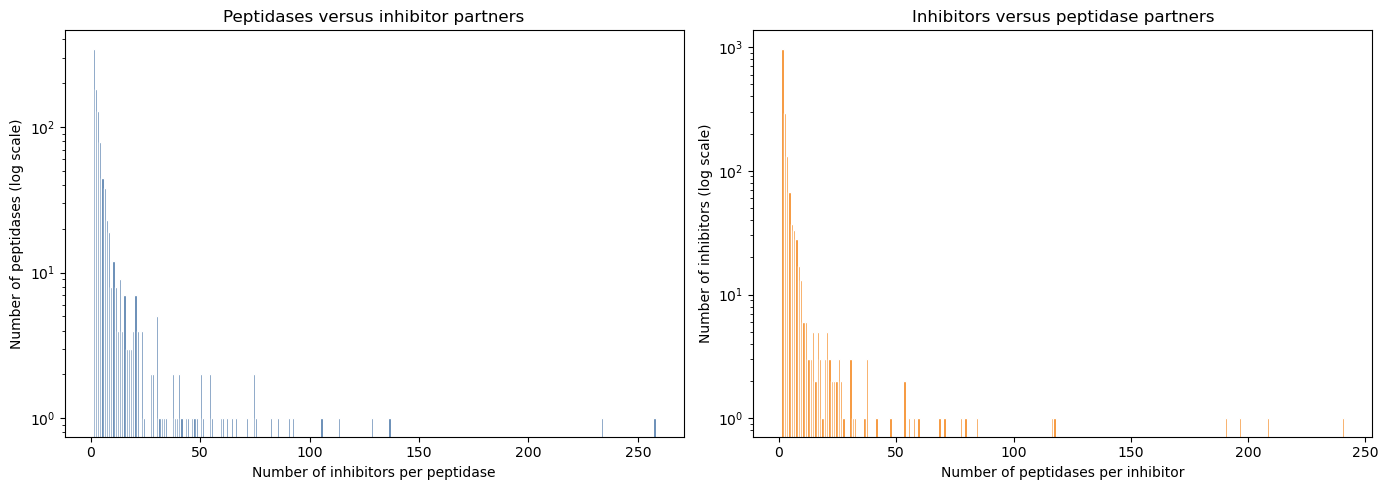

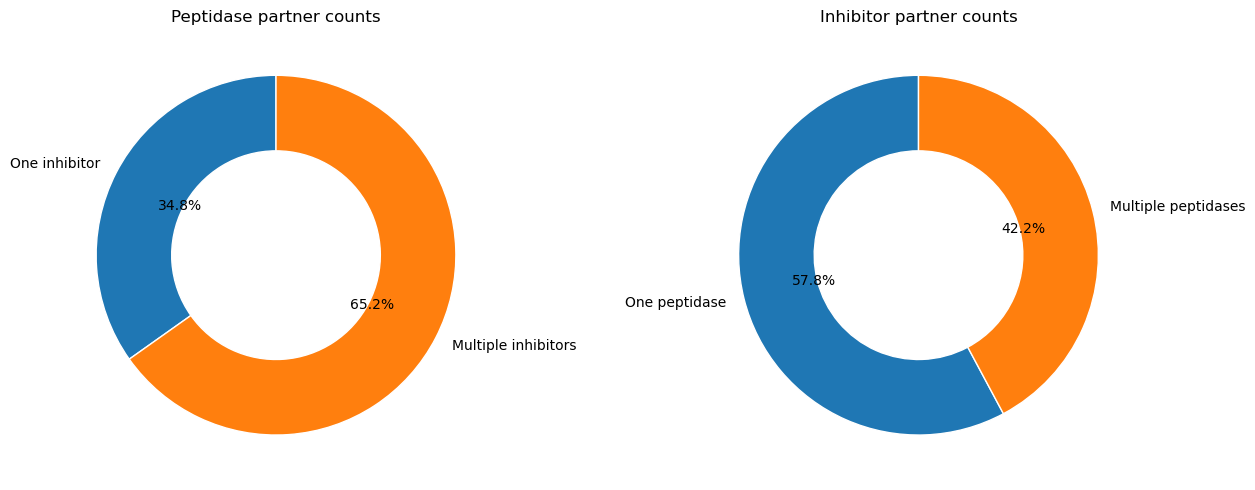

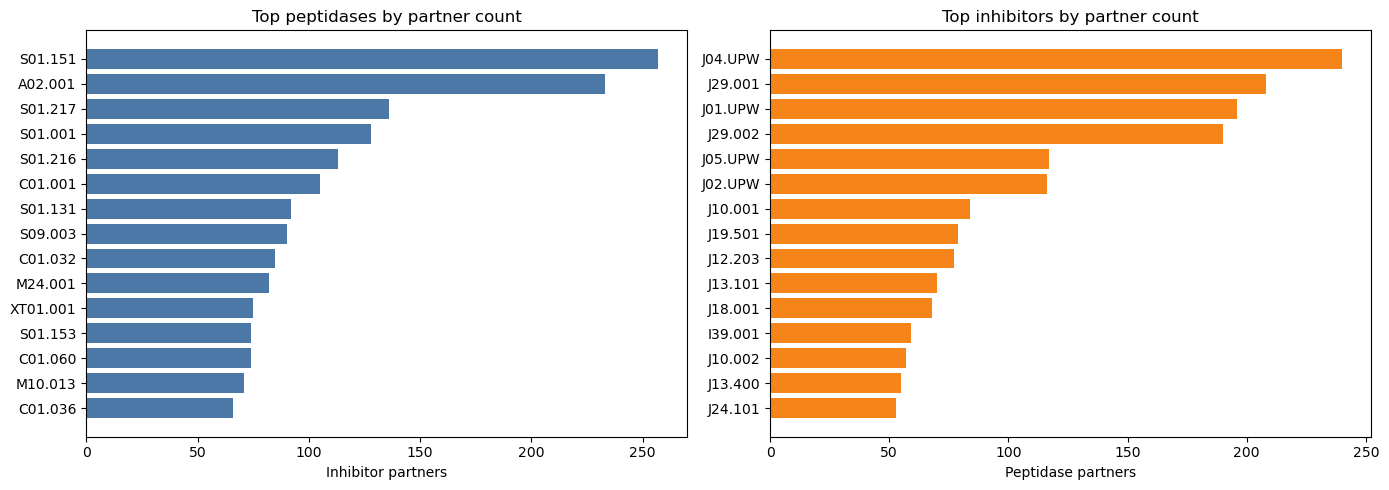

Peptidase partner summary:
One inhibitor          345
Multiple inhibitors    646
dtype: int64
Maximum inhibitor partners: 257

Inhibitor partner summary:
One peptidase          968
Multiple peptidases    706
dtype: int64
Maximum peptidase partners: 240


In [18]:
# Partner-count distributions for the peptidase-inhibitor complex table
complex_partners = pd.read_csv(COMPLEX_CSV, sep=";", encoding="latin1")

peptidase_partner_counts = complex_partners["peptidase_code"].value_counts()
inhibitor_partner_counts = complex_partners["inhibitor_code"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(peptidase_partner_counts, bins=range(1, peptidase_partner_counts.max() + 2),
             color="#4C78A8", edgecolor="white")
axes[0].set_yscale("log")
axes[0].set_xlabel("Number of inhibitors per peptidase")
axes[0].set_ylabel("Number of peptidases (log scale)")
axes[0].set_title("Peptidases versus inhibitor partners")

axes[1].hist(inhibitor_partner_counts, bins=range(1, inhibitor_partner_counts.max() + 2),
             color="#F58518", edgecolor="white")
axes[1].set_yscale("log")
axes[1].set_xlabel("Number of peptidases per inhibitor")
axes[1].set_ylabel("Number of inhibitors (log scale)")
axes[1].set_title("Inhibitors versus peptidase partners")

plt.tight_layout()
plt.show()

# Circular summary: exactly one partner versus more than one partner.
peptidase_summary = pd.Series({
    "One inhibitor": (peptidase_partner_counts == 1).sum(),
    "Multiple inhibitors": (peptidase_partner_counts > 1).sum(),
})
inhibitor_summary = pd.Series({
    "One peptidase": (inhibitor_partner_counts == 1).sum(),
    "Multiple peptidases": (inhibitor_partner_counts > 1).sum(),
})

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, counts, title in (
    (axes[0], peptidase_summary, "Peptidase partner counts"),
    (axes[1], inhibitor_summary, "Inhibitor partner counts"),
):
    ax.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90,
           wedgeprops={"width": 0.42, "edgecolor": "white"})
    ax.set_title(title)

plt.tight_layout()
plt.show()

# Top entities by number of partners.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

peptidase_top = peptidase_partner_counts.head(15).sort_values()
inhibitor_top = inhibitor_partner_counts.head(15).sort_values()

axes[0].barh(peptidase_top.index, peptidase_top.values, color="#4C78A8")
axes[0].set_xlabel("Inhibitor partners")
axes[0].set_title("Top peptidases by partner count")

axes[1].barh(inhibitor_top.index, inhibitor_top.values, color="#F58518")
axes[1].set_xlabel("Peptidase partners")
axes[1].set_title("Top inhibitors by partner count")

plt.tight_layout()
plt.show()

print("Peptidase partner summary:")
print(peptidase_summary)
print("Maximum inhibitor partners:", peptidase_partner_counts.max())
print("\nInhibitor partner summary:")
print(inhibitor_summary)
print("Maximum peptidase partners:", inhibitor_partner_counts.max())